# EDA — SYN DoS packets

**Purpose:** explore the silver table before designing gold and the model. Not a pipeline step (the Job will not run it).

**Reads from:** `kitsune_dev.silver.syn_dos_packets`

**Goals:**
1. Attack timeline: where attacks are and where the clean normal prefix ends
2. HH_jit timestamp hypothesis
3. Features by block: normal vs attack

## 1. Attack timeline

**What:** find the first and last attack packet (by `_row_number`) and count attack rows.

**Why:** the model will train only on normal traffic, so we need to know where the clean normal prefix ends.

**Result:** first/last attack row and number of attack rows.

In [0]:
from pyspark.sql import functions as F

# Same config pattern as 03
CATALOG = "kitsune_dev"
SILVER_PACKETS = f"{CATALOG}.silver.syn_dos_packets"

packets = spark.table(SILVER_PACKETS)

# Keep only attack rows, then get their first/last row number and count
attack_span = (
    packets
    .filter(F.col("label") == 1)
    .agg(
        F.min("_row_number").alias("first_attack"),
        F.max("_row_number").alias("last_attack"),
        F.count("*").alias("attack_rows"),
    )
)

display(attack_span)

# Keep the first attack row to reuse in the charts (no hardcoded numbers)
FIRST_ATTACK = attack_span.first()["first_attack"]
print(f"The first attack occurs on row:", FIRST_ATTACK)

first_attack,last_attack,attack_rows
2682350,2771276,7038


The first attack occurs on row: 2682350


**Findings:**
- First attack at row **2,682,350**, last attack at row **2,771,276** (the last row of the file). **7,038** attack packets in total.
- Rows **1 to 2,682,349** (96.8% of the data) are **100% normal**. This is the clean prefix we will use to train the model on normal traffic only, like the original Kitsune.
- The attack zone has 88,927 rows but only 7,038 attacks, so attacks are **mixed with normal traffic**, not one solid block (`last - first + 1 != attack_rows`).
- We do **not** train on every `label = 0` row: normal packets inside the attack zone come later in time, and their features summarize recent traffic that includes the attack.

### Attack timeline chart

**What:** group packets into bins of 10,000 rows and plot how many attacks fall in each bin.

**Why:** shows at a glance where the attack starts and that the first 96.8% of traffic is clean.

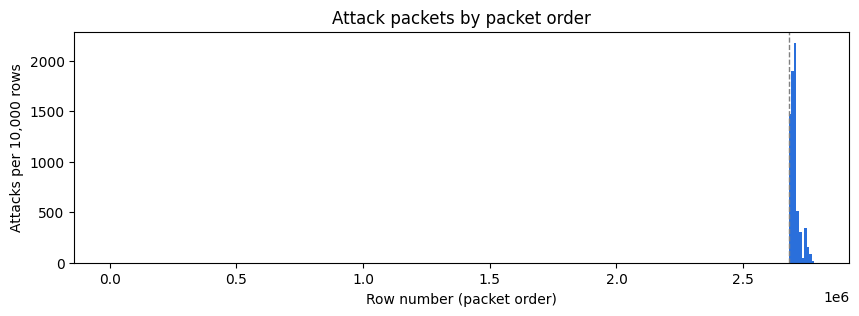

In [0]:
import matplotlib.pyplot as plt

BIN_SIZE = 10_000  # rows per bin

# Put each packet in a bin and count attacks per bin
attacks_per_bin = (
    packets
    .withColumn("bin", F.floor(F.col("_row_number") / BIN_SIZE))
    .groupBy("bin")
    .agg(F.sum("label").alias("attacks"))  # label is 0/1, so the sum = number of attacks
    .orderBy("bin")
    .toPandas()  # safe: only ~278 rows after the groupBy
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(attacks_per_bin["bin"] * BIN_SIZE, attacks_per_bin["attacks"],
       width=BIN_SIZE, color="#2a6fdb" , align="edge")
ax.axvline(FIRST_ATTACK, color="gray", linestyle="--", linewidth=1)  # first attack
ax.set_xlabel("Row number (packet order)")
ax.set_ylabel(f"Attacks per {BIN_SIZE:,} rows")
ax.set_title("Attack packets by packet order")
plt.show()

### Zoom: attack zone

**What:** only rows from 2,680,000 onward, bins of 1,000 rows, showing the share of attack packets per bin.

**Why:** the full chart squeezes the attack into the last 3%; zooming in shows how attacks mix with normal traffic.

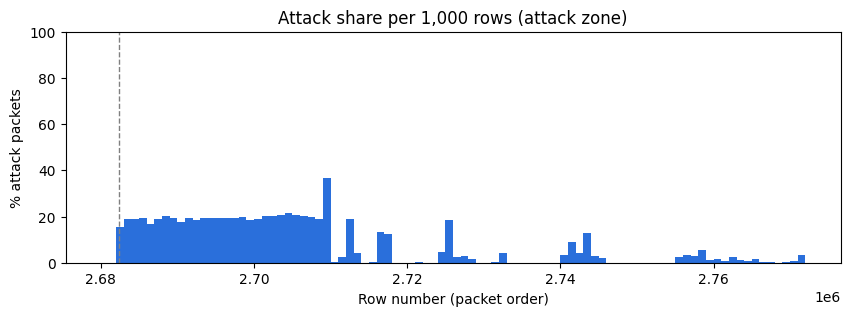

In [0]:
ZOOM_START = 2_680_000
ZOOM_BIN = 1_000  # rows per bin

# Share of attack packets per bin, only inside the attack zone
attack_share = (
    packets
    .filter(F.col("_row_number")>=ZOOM_START)
    .withColumn("bin", F.floor(F.col("_row_number") / ZOOM_BIN))
    .groupBy("bin")
    .agg(F.avg("label").alias("attack_share"))  # avg of 0/1 = share of attacks
    .orderBy("bin")
    .toPandas()  # ~92 rows
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(attack_share["bin"] * ZOOM_BIN, attack_share["attack_share"] * 100,
       width=ZOOM_BIN, color="#2a6fdb", align="edge")
ax.axvline(FIRST_ATTACK, color="gray", linestyle="--", linewidth=1)  # first attack
ax.set_ylim(0, 100)  # fixed 0-100% scale so the share is not exaggerated
ax.set_xlabel("Row number (packet order)")
ax.set_ylabel("% attack packets")
ax.set_title(f"Attack share per {ZOOM_BIN:,} rows (attack zone)")
plt.show()

**Findings:**
- The attack never takes over the traffic: the highest bin is **~37%** attack packets. Normal traffic keeps flowing during the attack.
- **Two phases:** a sustained flood (rows ~ 2,682k – 2,710k) at a steady **~20%** attack share, then **short bursts** separated by bins with 0% attacks.
- Confirms training on the clean prefix only: normal bins inside the attack zone sit right next to attack bursts.
- For evaluation: the low-share bursts (2–5%) will be harder to detect than the sustained flood, so we should look at how the model does on each phase, not only the overall score.

- Caveat: the x-axis is packet order, not time. Bins hold 1,000 packets each but cover different time spans, so these charts show the *share* of attack packets, not attack intensity over time.

## 2. HH_jit timestamp hypothesis

**What:** count rows where `hh_jit_l0_01_mean` (average time gap between packets) is larger than 1e9 seconds (~31 years).

**Why:** a real time gap can't be 31 years. If such values exist, they are probably full Unix timestamps leaked by the feature extractor, not real gaps.

**Result:** min, max and number of "impossible" values.

In [0]:
TIMESTAMP_THRESHOLD = 1e9  # 1e9 seconds = ~31 years: no real gap is this big
col = F.col("hh_jit_l0_01_mean")

jit_check = packets.agg(
    F.min(col).alias("min_value"),
    F.max(col).alias("max_value"),
    F.count_if(col >= TIMESTAMP_THRESHOLD).alias("rows_above_threshold"),
    F.from_unixtime(F.max(col)).alias("max_as_date"),  # seconds since 1970 -> readable date
)

display(jit_check)

min_value,max_value,rows_above_threshold,max_as_date
0.003098576929746486,1.488014482046588E9,537,2017-02-25 09:21:22


**Findings:**
- **537** rows have `hh_jit_l0_01_mean` above 1e9 seconds (~31 years), which is impossible for a real time gap.
- The max value, **1,488,014,482**, converts to **2017-02-25 09:21 UTC**, a real date from when the dataset was recorded. This supports the hypothesis: these are full Unix timestamps, not gaps.
- The min value (~3 ms) is a normal gap, so the column **mixes two kinds of values** about 500 billion times apart.
- Open question: this column is a running average, so a leaked timestamp may also inflate the following rows below the 1e9 threshold. To check next.


### All 5 HH_jit mean columns

**What:** count values above 1e9 in each HH_jit mean column (one per time window λ), in a single pass.

**Why:** if the timestamp leak is real, it should show up in every window, not just λ = 0.01.

In [0]:
from src.kitsune.feature_names import feature_names

# The 5 HH_jit mean columns (one per time window)
jit_mean_cols = []
for c in feature_names():
    if c.startswith("hh_jit") and c.endswith("_mean"):
        jit_mean_cols.append(c)

print(jit_mean_cols)

# One count per column, all computed in a single pass over the data
count_exprs = []
for c in jit_mean_cols:
    count_exprs.append(F.count_if(F.col(c) >= TIMESTAMP_THRESHOLD).alias(c))

jit_counts = packets.agg(*count_exprs)
display(jit_counts)

['hh_jit_l5_mean', 'hh_jit_l3_mean', 'hh_jit_l1_mean', 'hh_jit_l0_1_mean', 'hh_jit_l0_01_mean']


hh_jit_l5_mean,hh_jit_l3_mean,hh_jit_l1_mean,hh_jit_l0_1_mean,hh_jit_l0_01_mean
537,537,537,537,537



**Findings:**
- All 5 HH_jit mean columns have exactly **537** values above 1e9, one count per time window.
- Same count in every window → these are most likely the **first packet of 537 new conversations**: with only one sample, the mean equals that sample (the leaked timestamp) no matter how fast the window forgets.
- Open question: from the second packet on, the mean drops below 1e9 but can still be absurd (e.g. hundreds of millions of seconds). The 1e9 threshold only catches the first packet.

### Contaminated rows after the first packet

**What:** count values above 11 days (in seconds) in each HH_jit mean column.

**Why:** the 1e9 threshold only catches the first packet of each conversation. The mean is a running average, so the leaked timestamp keeps inflating the next packets below 1e9. 11 days is still an impossible gap between two packets of the same conversation.

In [0]:
CONTAMINATION_THRESHOLD = 11 * 24 * 60 * 60  # ~11 days in seconds

# jit_mean_cols already exists from 2b, reuse it
count_exprs = []
for c in jit_mean_cols:
    count_exprs.append(F.count_if(F.col(c) >= CONTAMINATION_THRESHOLD).alias(c))

contaminated_counts = packets.agg(*count_exprs)
display(contaminated_counts)

hh_jit_l5_mean,hh_jit_l3_mean,hh_jit_l1_mean,hh_jit_l0_1_mean,hh_jit_l0_01_mean
1577,2170,3984,7990,10427


**Findings:**
- Every window has more than 537 contaminated rows: the leak spreads past the first packet.
- The count grows as λ gets smaller: **1,577** (λ=5) → 2,170 → 3,984 → 7,990 → **10,427** (λ=0.01). Small λ means slow forgetting, so the leaked timestamp stays in the mean for more packets (~3 per conversation at λ=5 vs ~19 at λ=0.01).
- Only ~0.38% of rows, but the values are extreme (up to 1.5e9). One value like that is enough to break min-max scaling for the whole column, so this must be handled in gold.